# Training Pipeline Face Anti Spoofing Butkem AI (Simplified Linear Head)

Notebook ini merupakan kelanjutan dari notebook EDA_Train_Butkem_AI dan berisi pipeline lengkap untuk membangun model klasifikasi Real vs Spoof, mulai dari persiapan data sampai inference untuk data baru.

**Versi ini disederhanakan** dibanding versi sebelumnya: classifier head diganti dari ArcFace menjadi Linear biasa (konsisten dengan pipeline ConvNeXt), dan augmentasi diganti menjadi versi konservatif (hanya modifikasi spasial dan kontras ringan, tanpa blur/noise/rotasi/dropout).

Ringkasan alur kerja yang ada di notebook ini:

1. Setup environment dan reproducibility
2. Loading dataset serta pembagian data train, validation, dan test secara stratified
3. Pipeline augmentasi konservatif dan dataloader dengan penanganan class imbalance
4. Arsitektur model: backbone pretrained langsung ke classifier Linear
5. Training dengan strategi anti overfitting dan anti underfitting
6. Evaluasi menggunakan macro F1 beserta confusion matrix dan classification report
7. Visualisasi ruang fitur (feature backbone) menggunakan t SNE
8. Analisis interpretabilitas menggunakan Grad CAM untuk melihat area gambar yang paling berkontribusi terhadap prediksi setiap kelas (misalnya fake_mask, fake_print, realperson)
9. Fungsi inference siap pakai untuk gambar baru

## 1. Setup Environment

In [1]:
import sys, subprocess
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'timm', 'grad-cam', 'albumentations', 'scikit-learn', 'umap-learn'])


## 2. Mount Google Drive dan Konfigurasi
Struktur folder mengikuti notebook EDA sebelumnya yaitu `Butkem_AI/train` dengan sub folder `realperson` dan beberapa folder `fake_...` untuk tiap jenis spoof.

In [2]:
import os
import sys
import glob

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/ButkemAI'
    if not os.path.exists(os.path.join(BASE_DIR, 'train')):
        candidates = glob.glob('/content/drive/**/ButkemAI/train', recursive=True)
        if candidates:
            BASE_DIR = os.path.dirname(candidates[0])
else:
    BASE_DIR = 'D:/Bagas/BootcampAI2026/Convnext'

DATA_DIR = os.path.join(BASE_DIR, 'train')
ARTIFACT_DIR = os.path.join(BASE_DIR, 'artifacts')
os.makedirs(ARTIFACT_DIR, exist_ok=True)
print('DATA_DIR:', DATA_DIR)
print('ARTIFACT_DIR:', ARTIFACT_DIR)


## 3. Import Library

In [3]:
import os
import cv2
import json
import random
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              f1_score, precision_recall_fscore_support,
                              roc_auc_score)
from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE

import warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device yang dipakai:', DEVICE)

Device yang dipakai: cuda


## 4. Reproducibility
Semua random seed dikunci agar hasil training dapat direproduksi dan perbandingan eksperimen menjadi adil.

In [4]:
SEED = 42

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

## 4.1 Cek Nama Folder Asli
Langkah ini sengaja ditambahkan untuk memastikan nama folder yang terbaca oleh kode benar benar sesuai dengan yang ada di Google Drive, sebelum dipakai untuk labeling Real dan Spoof.

In [5]:
print('Isi folder', DATA_DIR, ':')
for name in sorted(os.listdir(DATA_DIR)):
    full_path = os.path.join(DATA_DIR, name)
    if os.path.isdir(full_path) and not name.startswith(('_', '.')):
        jumlah_file = len(os.listdir(full_path))
        print(f'  {name}  (jumlah file: {jumlah_file})')


Isi folder D:/Bagas/BootcampAI2026/Convnext/train :
  __pycache__  (jumlah file: 1)
  fake_mannequin  (jumlah file: 203)
  fake_mask  (jumlah file: 284)
  fake_printed  (jumlah file: 143)
  fake_screen  (jumlah file: 204)
  fake_unknown  (jumlah file: 380)
  realperson  (jumlah file: 438)


## 5. Loading Dataset
Fungsi loader dibuat generik sehingga otomatis mendeteksi semua folder `fake_...` yang ada, bukan hanya satu jenis spoof saja. Label utama tetap Real dan Spoof, sedangkan `original_class` dipakai sebagai label granular (multi kelas) untuk supervisi yang lebih kaya sekaligus untuk analisis interpretabilitas per jenis serangan.

In [6]:
def load_image_paths(data_dir, deduplicate=True):
    file_paths, labels, original_classes, hashes = [], [], [], []

    if not os.path.exists(data_dir):
        raise FileNotFoundError(f'{data_dir} tidak ditemukan')

    for class_name in sorted(os.listdir(data_dir)):
        class_dir = os.path.join(data_dir, class_name)
        if not os.path.isdir(class_dir) or class_name.startswith(('_', '.')):
            continue

        # Pencocokan pakai awalan (prefix), bukan exact match
        name_lower = class_name.lower()
        if name_lower.startswith('realperson'):
            label = 'Real'
        elif name_lower.startswith('fake_') or name_lower.startswith('fake-'):
            label = 'Spoof'
        else:
            continue

        for img_name in sorted(os.listdir(class_dir)):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
                fpath = os.path.join(class_dir, img_name)
                file_paths.append(fpath)
                labels.append(label)
                original_classes.append(class_name)
                with open(fpath, 'rb') as f:
                    hashes.append(hashlib.md5(f.read()).hexdigest())

    raw_df = pd.DataFrame({
        'filepath': file_paths,
        'label': labels,
        'original_class': original_classes,
        'md5': hashes,
    })

    if not deduplicate or len(raw_df) == 0:
        return raw_df

    n_before = len(raw_df)
    # 1. Buang gambar yang memiliki hash identik tetapi berada di kelas berbeda (label conflict)
    label_nunique = raw_df.groupby('md5')['original_class'].transform('nunique')
    n_conflict = int((label_nunique > 1).sum())
    clean_df = raw_df[label_nunique == 1].copy()

    # 2. Hapus duplikat identik di dalam kelas yang sama (sisakan 1 per hash) untuk mencegah data leakage saat split
    n_within_dup = int(clean_df.duplicated(subset=['md5'], keep='first').sum())
    clean_df = clean_df.drop_duplicates(subset=['md5'], keep='first').reset_index(drop=True)

    print(f'Total gambar sebelum deduplikasi: {n_before}')
    print(f'Dihapus karena konflik lintas kelas: {n_conflict} | Duplikat dalam kelas: {n_within_dup}')
    return clean_df

df = load_image_paths(DATA_DIR, deduplicate=True)
print('Total gambar bersih (unik) ditemukan:', len(df))
print(df['original_class'].value_counts())
df.head()


Total gambar ditemukan: 1652
original_class
realperson        438
fake_unknown      380
fake_mask         284
fake_screen       204
fake_mannequin    203
fake_printed      143
Name: count, dtype: int64


,filepath,label,original_class
0,D:/Bagas/BootcampAI2026/Convnext/train\fake_ma...,Spoof,fake_mannequin
1,D:/Bagas/BootcampAI2026/Convnext/train\fake_ma...,Spoof,fake_mannequin
2,D:/Bagas/BootcampAI2026/Convnext/train\fake_ma...,Spoof,fake_mannequin
3,D:/Bagas/BootcampAI2026/Convnext/train\fake_ma...,Spoof,fake_mannequin
4,D:/Bagas/BootcampAI2026/Convnext/train\fake_ma...,Spoof,fake_mannequin


## 6. Label Encoding
Target training utama adalah klasifikasi multi kelas terhadap `original_class`. Label biner Real dan Spoof tetap disimpan untuk pelaporan metrik agregat, sehingga model bisa dievaluasi baik pada level granular maupun level keamanan (Real vs Spoof).

In [7]:
label_encoder = LabelEncoder()
df['class_id'] = label_encoder.fit_transform(df['original_class'])
NUM_CLASSES = len(label_encoder.classes_)
print('Jumlah kelas:', NUM_CLASSES)
print(dict(zip(label_encoder.classes_, range(NUM_CLASSES))))

real_mask = (df['label'] == 'Real').values
spoof_class_ids = sorted(df.loc[~real_mask, 'class_id'].unique().tolist())
real_class_ids = sorted(df.loc[real_mask, 'class_id'].unique().tolist())

Jumlah kelas: 6
{'fake_mannequin': 0, 'fake_mask': 1, 'fake_printed': 2, 'fake_screen': 3, 'fake_unknown': 4, 'realperson': 5}


## 7. Split Data Train, Validation, Test
Split dilakukan secara stratified berdasarkan `original_class` (bukan hanya label biner) supaya proporsi tiap jenis spoof tetap konsisten di ketiga subset. Rasio yang dipakai adalah 70 persen train, 15 persen validation, 15 persen test. Test set hanya disentuh sekali di akhir untuk evaluasi final agar tidak terjadi kebocoran informasi (data leakage) selama proses tuning.

In [8]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df['class_id'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['class_id'], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('Train:', len(train_df), 'Validation:', len(val_df), 'Test:', len(test_df))
print()
print('Distribusi kelas pada train set:')
print(train_df['original_class'].value_counts())

Train: 1156 Validation: 248 Test: 248

Distribusi kelas pada train set:
original_class
realperson        306
fake_unknown      266
fake_mask         199
fake_screen       143
fake_mannequin    142
fake_printed      100
Name: count, dtype: int64


## 8. Augmentasi dan Dataset
Augmentasi diset konservatif tapi efektif: hanya modifikasi spasial (resize, flip) dan kontras/warna ringan (ColorJitter). Tidak memakai blur, noise, rotasi, atau dropout supaya sinyal tekstur halus (moire, halftone) yang penting untuk membedakan jenis spoof tidak ikut rusak, sekaligus menjaga augmentasi tetap sederhana dan cepat.

In [9]:
IMG_SIZE = 224

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

eval_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

In [10]:
class SpoofDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row['filepath'])
        if img is None:
            img = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transform:
            img = self.transform(image=img)['image']

        class_id = torch.tensor(row['class_id'], dtype=torch.long)
        binary_id = torch.tensor(0 if row['label'] == 'Real' else 1, dtype=torch.long)
        return img, class_id, binary_id

train_dataset = SpoofDataset(train_df, train_transform)
val_dataset = SpoofDataset(val_df, eval_transform)
test_dataset = SpoofDataset(test_df, eval_transform)

## 9. Penanganan Class Imbalance
Menggunakan `WeightedRandomSampler` pada train loader supaya setiap batch cenderung lebih seimbang antar kelas, dikombinasikan dengan class weight pada loss function sebagai lapisan proteksi kedua terhadap ketidakseimbangan data.

In [11]:
class_counts = train_df['class_id'].value_counts().sort_index()
class_weights = 1.0 / class_counts
sample_weights = train_df['class_id'].map(class_weights).values

# Gunakan WeightedRandomSampler untuk menyeimbangkan distribusi kelas di setiap batch training.
# Catatan metodologi: Jika USE_SAMPLER = True, jangan menggandakan bobot kelas di CrossEntropyLoss
# supaya kelas minoritas tidak ter-overweight secara kuadratik ((1/N_c)^2).
USE_SAMPLER = True

sampler = WeightedRandomSampler(
    weights=sample_weights, num_samples=len(sample_weights), replacement=True
)

BATCH_SIZE = 32

if USE_SAMPLER:
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler,
                               num_workers=0, pin_memory=True, drop_last=True)
else:
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=0, pin_memory=True, drop_last=True)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=True)

class_weight_tensor = torch.tensor(
    (1.0 / class_counts).values.copy(), dtype=torch.float32
)
class_weight_tensor = class_weight_tensor / class_weight_tensor.sum() * NUM_CLASSES
class_weight_tensor = class_weight_tensor.to(DEVICE)


## 10. Arsitektur Model
Model terdiri dari dua bagian saja.

1. Backbone yaitu EfficientNet B0 yang sudah dipretrained pada ImageNet, dipakai sebagai feature extractor, menghasilkan feature vector 1280 dimensi.
2. Classifier Head yaitu satu layer Linear yang memetakan feature vector 1280 dimensi langsung ke jumlah kelas, tanpa proyeksi embedding maupun margin sudut (ArcFace). Pendekatan ini lebih sederhana dan konsisten dengan pipeline ConvNeXt, sekaligus lebih cepat konvergen pada dataset yang relatif kecil.

Backbone dibekukan (frozen) di awal training lalu di unfreeze bertahap (progressive unfreezing) supaya model tidak langsung overfit pada dataset yang relatif kecil.

In [12]:
class EfficientNetModel(nn.Module):
    def __init__(self, num_classes, backbone_name='efficientnet_b0', pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)
        self.fc = nn.Linear(self.backbone.num_features, num_classes)

    def forward(self, x):
        features = self.backbone(x)
        logits = self.fc(features)
        return logits

    def freeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = False

    def unfreeze_backbone(self, num_last_blocks=None):
        if num_last_blocks is None:
            for param in self.backbone.parameters():
                param.requires_grad = True
        else:
            params = list(self.backbone.parameters())
            for param in params[-num_last_blocks:]:
                param.requires_grad = True


model = EfficientNetModel(num_classes=NUM_CLASSES).to(DEVICE)
model.freeze_backbone()
print('Total parameter trainable saat backbone dibekukan:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Total parameter model keseluruhan:',
      sum(p.numel() for p in model.parameters()))

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Total parameter trainable saat backbone dibekukan: 7686
Total parameter model keseluruhan: 4015234


## 11. Loss Function dan Optimizer
Menggunakan Cross Entropy dengan class weight serta label smoothing kecil (0.05) supaya model tidak terlalu percaya diri (overconfident) pada training set, yang membantu generalisasi ke data baru. Optimizer memakai AdamW dengan weight decay sebagai regularisasi tambahan, dikombinasikan scheduler cosine annealing dengan warmup singkat.

In [13]:
# Jika WeightedRandomSampler sudah aktif (USE_SAMPLER=True), batch training sudah seimbang,
# sehingga loss_weight diset None agar tidak terjadi double imbalance compensation
# dan agar skala train_loss tetap sebanding dengan val_loss.
loss_weight = None if USE_SAMPLER else class_weight_tensor
criterion = nn.CrossEntropyLoss(weight=loss_weight, label_smoothing=0.05)

LR_HEAD = 1e-3
LR_BACKBONE = 1e-4
WEIGHT_DECAY = 1e-4
EPOCHS_STAGE1 = 8
EPOCHS_STAGE2 = 20

optimizer = torch.optim.AdamW([
    {'params': model.fc.parameters(), 'lr': LR_HEAD},
    {'params': model.backbone.parameters(), 'lr': LR_BACKBONE},
], weight_decay=WEIGHT_DECAY)

scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))


## 12. Utility Training, Validasi, dan Early Stopping
Fungsi `run_epoch` dipakai baik untuk training maupun validasi. Macro F1 dihitung setiap epoch pada validation set dan menjadi acuan utama untuk checkpointing model terbaik serta early stopping, karena macro F1 memberi bobot yang sama untuk setiap kelas walaupun jumlah sampelnya tidak seimbang.

In [14]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds, all_targets = [], []

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for imgs, class_ids, _ in tqdm(loader, leave=False):
            imgs = imgs.to(DEVICE, non_blocking=True)
            class_ids = class_ids.to(DEVICE, non_blocking=True)

            if is_train:
                optimizer.zero_grad()
                with torch.amp.autocast('cuda', enabled=(DEVICE.type == 'cuda')):
                    logits = model(imgs)
                    loss = criterion(logits, class_ids)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                logits = model(imgs)
                loss = criterion(logits, class_ids)

            total_loss += loss.item() * imgs.size(0)
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(class_ids.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    return avg_loss, macro_f1, all_preds, all_targets


class EarlyStopping:
    def __init__(self, patience=6, mode='max'):
        self.patience = patience
        self.mode = mode
        self.best_score = None
        self.counter = 0
        self.should_stop = False

    def reset(self):
        """Reset counter dan flag should_stop saat berpindah tahap training (Stage 1 -> Stage 2)."""
        self.counter = 0
        self.should_stop = False

    def step(self, score):
        if self.best_score is None:
            self.best_score = score
            return True

        improved = (score > self.best_score) if self.mode == 'max' else (score < self.best_score)
        if improved:
            self.best_score = score
            self.counter = 0
            self.should_stop = False
            return True
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
            return False


## 13. Proses Training Dua Tahap
Tahap pertama hanya melatih embedding head dan arc margin dengan backbone dibekukan agar bobot pretrained tidak rusak di awal training. Tahap kedua melakukan fine tuning menyeluruh dengan learning rate lebih kecil pada backbone. Kombinasi early stopping, checkpoint model terbaik berdasarkan validation macro F1, serta pemantauan gap antara train loss dan validation loss dipakai untuk mendeteksi overfitting maupun underfitting secara langsung selama training berlangsung.

In [15]:
history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}
best_ckpt_path = os.path.join(ARTIFACT_DIR, 'best_model.pt')
early_stopper = EarlyStopping(patience=6, mode='max')

def train_stage(model, epochs, scheduler=None, label=''):
    for epoch in range(epochs):
        train_loss, train_f1, _, _ = run_epoch(model, train_loader, criterion, optimizer, scaler)
        val_loss, val_f1, _, _ = run_epoch(model, val_loader, criterion)

        if scheduler is not None:
            scheduler.step()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_f1'].append(train_f1)
        history['val_f1'].append(val_f1)

        gap = train_f1 - val_f1
        print(f'[{label}] Epoch {epoch+1}/{epochs} | '
              f'train_loss {train_loss:.4f} val_loss {val_loss:.4f} | '
              f'train_f1 {train_f1:.4f} val_f1 {val_f1:.4f} | gap {gap:.4f}')

        improved = early_stopper.step(val_f1)
        if improved:
            torch.save({
                'model_state_dict': model.state_dict(),
                'label_encoder_classes': label_encoder.classes_.tolist(),
                'img_size': IMG_SIZE,
                'backbone': 'efficientnet_b0',
            }, best_ckpt_path)
            print('  > Checkpoint terbaik disimpan pada macro F1 val =', round(val_f1, 4))

        if early_stopper.should_stop:
            print('  > Early stopping dipicu, menghentikan training tahap ini.')
            break

# Tahap 1: freeze backbone, latih head saja
model.freeze_backbone()
print('=== Tahap 1: Melatih embedding head dengan backbone dibekukan ===')
train_stage(model, EPOCHS_STAGE1, label='stage1')

=== Tahap 1: Melatih embedding head dengan backbone dibekukan ===


  0%|          | 0/36 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

[stage1] Epoch 1/8 | train_loss 1.3103 val_loss 1.1050 | train_f1 0.4769 val_f1 0.7017 | gap -0.2248
  > Checkpoint terbaik disimpan pada macro F1 val = 0.7017


  0%|          | 0/36 [00:00<?, ?it/s]

...

  0%|          | 0/8 [00:00<?, ?it/s]

[stage1] Epoch 7/8 | train_loss 0.5120 val_loss 0.6958 | train_f1 0.8906 val_f1 0.8447 | gap 0.0459
  > Checkpoint terbaik disimpan pada macro F1 val = 0.8447


  0%|          | 0/36 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

[stage1] Epoch 8/8 | train_loss 0.4807 val_loss 0.6766 | train_f1 0.9192 val_f1 0.8408 | gap 0.0783


In [16]:
# Tahap 2: muat kembali bobot terbaik dari Tahap 1, lalu unfreeze seluruh backbone untuk fine-tuning
print('=== Tahap 2: Fine tuning menyeluruh ===')
if os.path.exists(best_ckpt_path):
    ckpt_stage1 = torch.load(best_ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt_stage1['model_state_dict'])
    print('  > Memuat checkpoint terbaik dari Tahap 1 sebelum unfreeze backbone.')

model.unfreeze_backbone()
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_STAGE2)
early_stopper.reset()
train_stage(model, EPOCHS_STAGE2, scheduler=scheduler, label='stage2')


=== Tahap 2: Fine tuning menyeluruh ===


  0%|          | 0/36 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

[stage2] Epoch 1/20 | train_loss 0.4343 val_loss 0.6637 | train_f1 0.9249 val_f1 0.8360 | gap 0.0889


  0%|          | 0/36 [00:00<?, ?it/s]

...

  0%|          | 0/8 [00:00<?, ?it/s]

[stage2] Epoch 12/20 | train_loss 0.2657 val_loss 0.5780 | train_f1 0.9947 val_f1 0.9142 | gap 0.0806


  0%|          | 0/36 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

[stage2] Epoch 13/20 | train_loss 0.2670 val_loss 0.5518 | train_f1 0.9947 val_f1 0.9167 | gap 0.0780
  > Early stopping dipicu, menghentikan training tahap ini.


## 14. Kurva Training untuk Diagnosis Overfitting dan Underfitting
Pola yang diharapkan pada model yang sehat adalah train loss dan validation loss sama sama menurun lalu stabil berdekatan (bukan train loss terus turun sementara validation loss naik, yang menandakan overfitting), dan macro F1 keduanya mencapai nilai tinggi yang berdekatan (bukan sama sama rendah, yang menandakan underfitting).

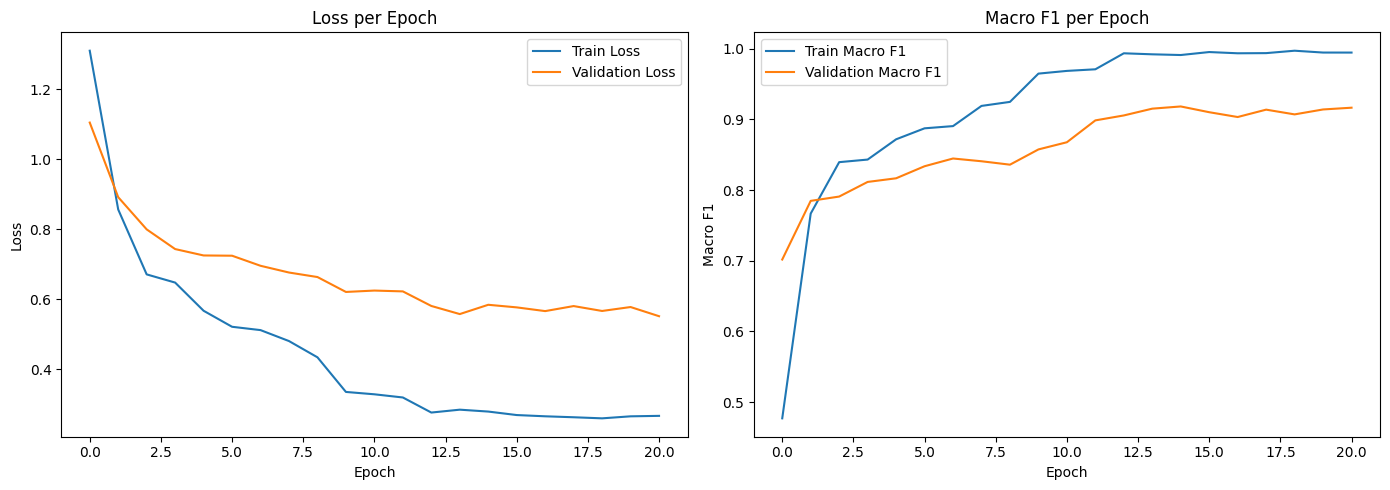

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Validation Loss')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history['train_f1'], label='Train Macro F1')
axes[1].plot(history['val_f1'], label='Validation Macro F1')
axes[1].set_title('Macro F1 per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Macro F1')
axes[1].legend()

plt.tight_layout()
plt.show()

## 15. Load Model Terbaik dan Evaluasi Akhir pada Test Set
Test set sama sekali belum pernah dilihat model selama training maupun pemilihan hyperparameter, sehingga hasil pada bagian ini merepresentasikan estimasi paling jujur terhadap kemampuan generalisasi model.

In [18]:
checkpoint = torch.load(best_ckpt_path, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print('Model terbaik berhasil dimuat.')

test_loss, test_macro_f1, test_preds, test_targets = run_epoch(model, test_loader, criterion)
print('Test loss:', round(test_loss, 4))
print('Test macro F1:', round(test_macro_f1, 4))

Model terbaik berhasil dimuat.


  0%|          | 0/8 [00:00<?, ?it/s]

Test loss: 0.5273
Test macro F1: 0.9087


                precision    recall  f1-score   support

fake_mannequin     0.8824    0.9677    0.9231        31
     fake_mask     0.8372    0.8571    0.8471        42
  fake_printed     0.8750    0.9545    0.9130        22
   fake_screen     1.0000    0.8667    0.9286        30
  fake_unknown     0.9636    0.9298    0.9464        57
    realperson     0.8939    0.8939    0.8939        66

      accuracy                         0.9073       248
     macro avg     0.9087    0.9116    0.9087       248
  weighted avg     0.9101    0.9073    0.9076       248



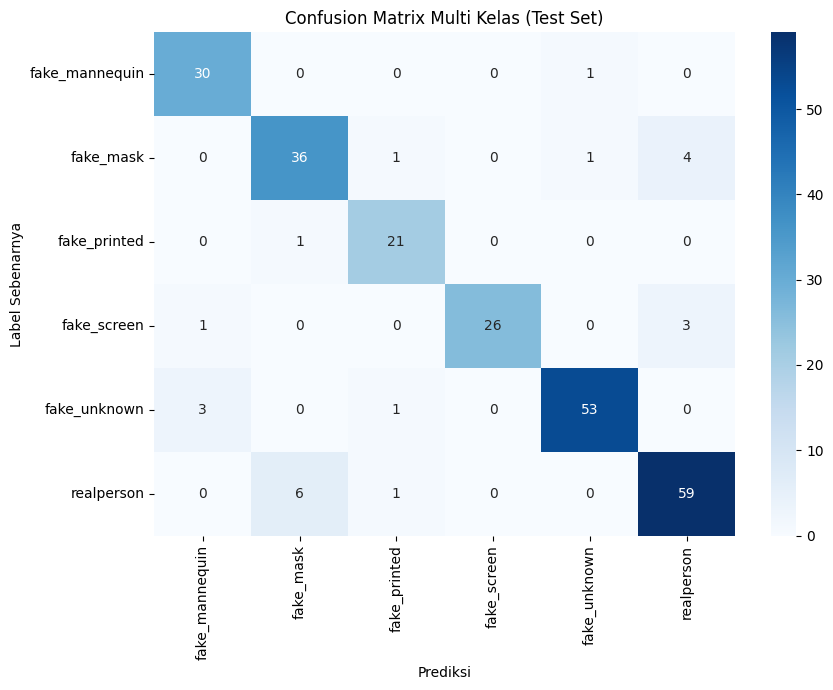

In [19]:
target_names = label_encoder.classes_
print(classification_report(test_targets, test_preds, target_names=target_names, digits=4))

cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix Multi Kelas (Test Set)')
plt.xlabel('Prediksi')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

## 16. Evaluasi Agregat Real vs Spoof
Selain evaluasi granular per jenis serangan, prediksi juga diagregasi menjadi dua kelas keamanan yaitu Real dan Spoof. Metrik ini yang paling relevan untuk konteks aplikasi keamanan siber karena pada akhirnya sistem hanya perlu memutuskan apakah wajah tersebut asli atau bukan.

Macro F1 (Real vs Spoof): 0.9277
              precision    recall  f1-score   support

        Real     0.8939    0.8939    0.8939        66
       Spoof     0.9615    0.9615    0.9615       182

    accuracy                         0.9435       248
   macro avg     0.9277    0.9277    0.9277       248
weighted avg     0.9435    0.9435    0.9435       248



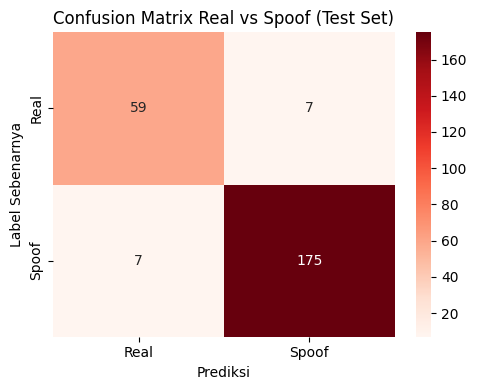

In [20]:
def map_to_binary(class_ids, spoof_ids):
    return np.array([1 if c in spoof_ids else 0 for c in class_ids])

test_targets_bin = map_to_binary(test_targets, spoof_class_ids)
test_preds_bin = map_to_binary(test_preds, spoof_class_ids)

print('Macro F1 (Real vs Spoof):', round(f1_score(test_targets_bin, test_preds_bin, average='macro'), 4))
print(classification_report(test_targets_bin, test_preds_bin, target_names=['Real', 'Spoof'], digits=4))

cm_bin = confusion_matrix(test_targets_bin, test_preds_bin)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_bin, annot=True, fmt='d', cmap='Reds', xticklabels=['Real','Spoof'], yticklabels=['Real','Spoof'])
plt.title('Confusion Matrix Real vs Spoof (Test Set)')
plt.xlabel('Prediksi')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

## 17. Visualisasi Ruang Fitur Backbone (t SNE)
Karena model versi ini tidak lagi punya layer embedding terpisah, fitur yang divisualisasikan diambil langsung dari output backbone (1280 dimensi, sebelum masuk ke classifier `fc`). Bagian ini memeriksa apakah fitur yang dipelajari backbone benar benar terpisah antar kelas. Jika titik titik tiap kelas membentuk kluster yang jelas terpisah, artinya model belajar representasi yang bermakna dan tidak hanya menghafal (memorisasi) data training, yang merupakan indikasi generalisasi yang baik.

  0%|          | 0/8 [00:00<?, ?it/s]

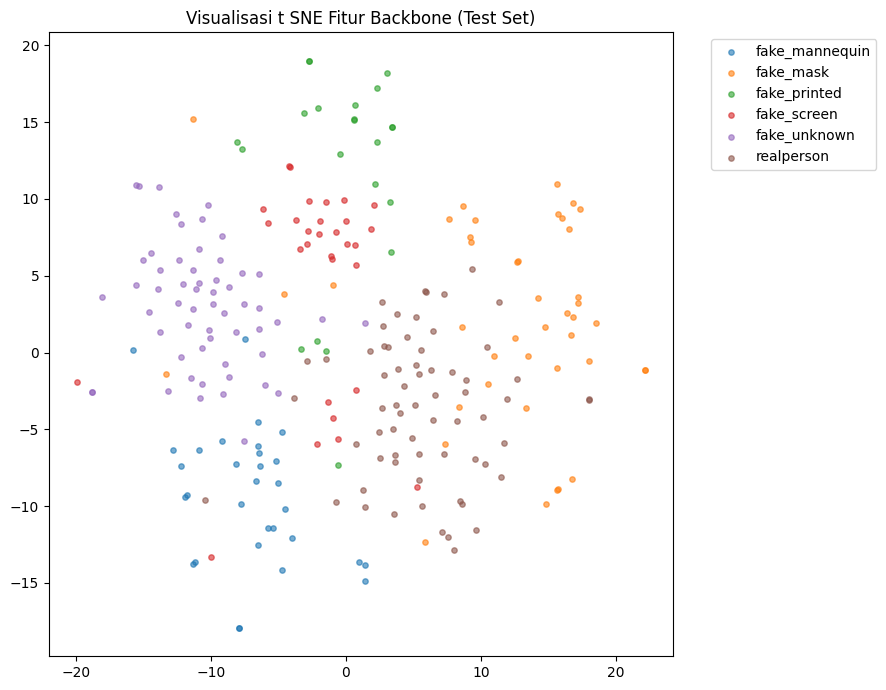

In [21]:
def extract_backbone_features(model, loader):
    model.eval()
    all_features, all_labels = [], []
    with torch.no_grad():
        for imgs, class_ids, _ in tqdm(loader, leave=False):
            imgs = imgs.to(DEVICE)
            features = model.backbone(imgs)
            all_features.append(features.cpu().numpy())
            all_labels.append(class_ids.numpy())
    return np.concatenate(all_features), np.concatenate(all_labels)

test_features, test_labels = extract_backbone_features(model, test_loader)

tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
embeddings_2d = tsne.fit_transform(test_features)

plt.figure(figsize=(9, 7))
for class_id in np.unique(test_labels):
    mask = test_labels == class_id
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
                label=label_encoder.classes_[class_id], alpha=0.6, s=15)
plt.title('Visualisasi t SNE Fitur Backbone (Test Set)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 18. Interpretabilitas dengan Grad CAM
Bagian ini menjawab pertanyaan area mana pada gambar yang paling banyak dipakai model untuk mengenali suatu kelas, misalnya apakah model fokus pada tekstur kulit dan mata saat mengenali `realperson`, atau fokus pada tepi masker dan area mulut saat mengenali `fake_mask`, atau fokus pada pantulan layar saat mengenali kelas spoof hasil rekam ulang layar. Analisis ini penting untuk memastikan model belajar sinyal spoofing yang relevan, bukan artefak yang tidak berhubungan (misalnya latar belakang atau watermark).

In [22]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Model versi ini sudah langsung mengembalikan logits tunggal (bukan tuple),
# jadi tidak perlu wrapper tambahan seperti versi ArcFace sebelumnya.
model.eval()

target_layer = model.backbone.conv_head if hasattr(model.backbone, 'conv_head') else model.backbone.blocks[-1]
gradcam = GradCAM(model=model, target_layers=[target_layer])

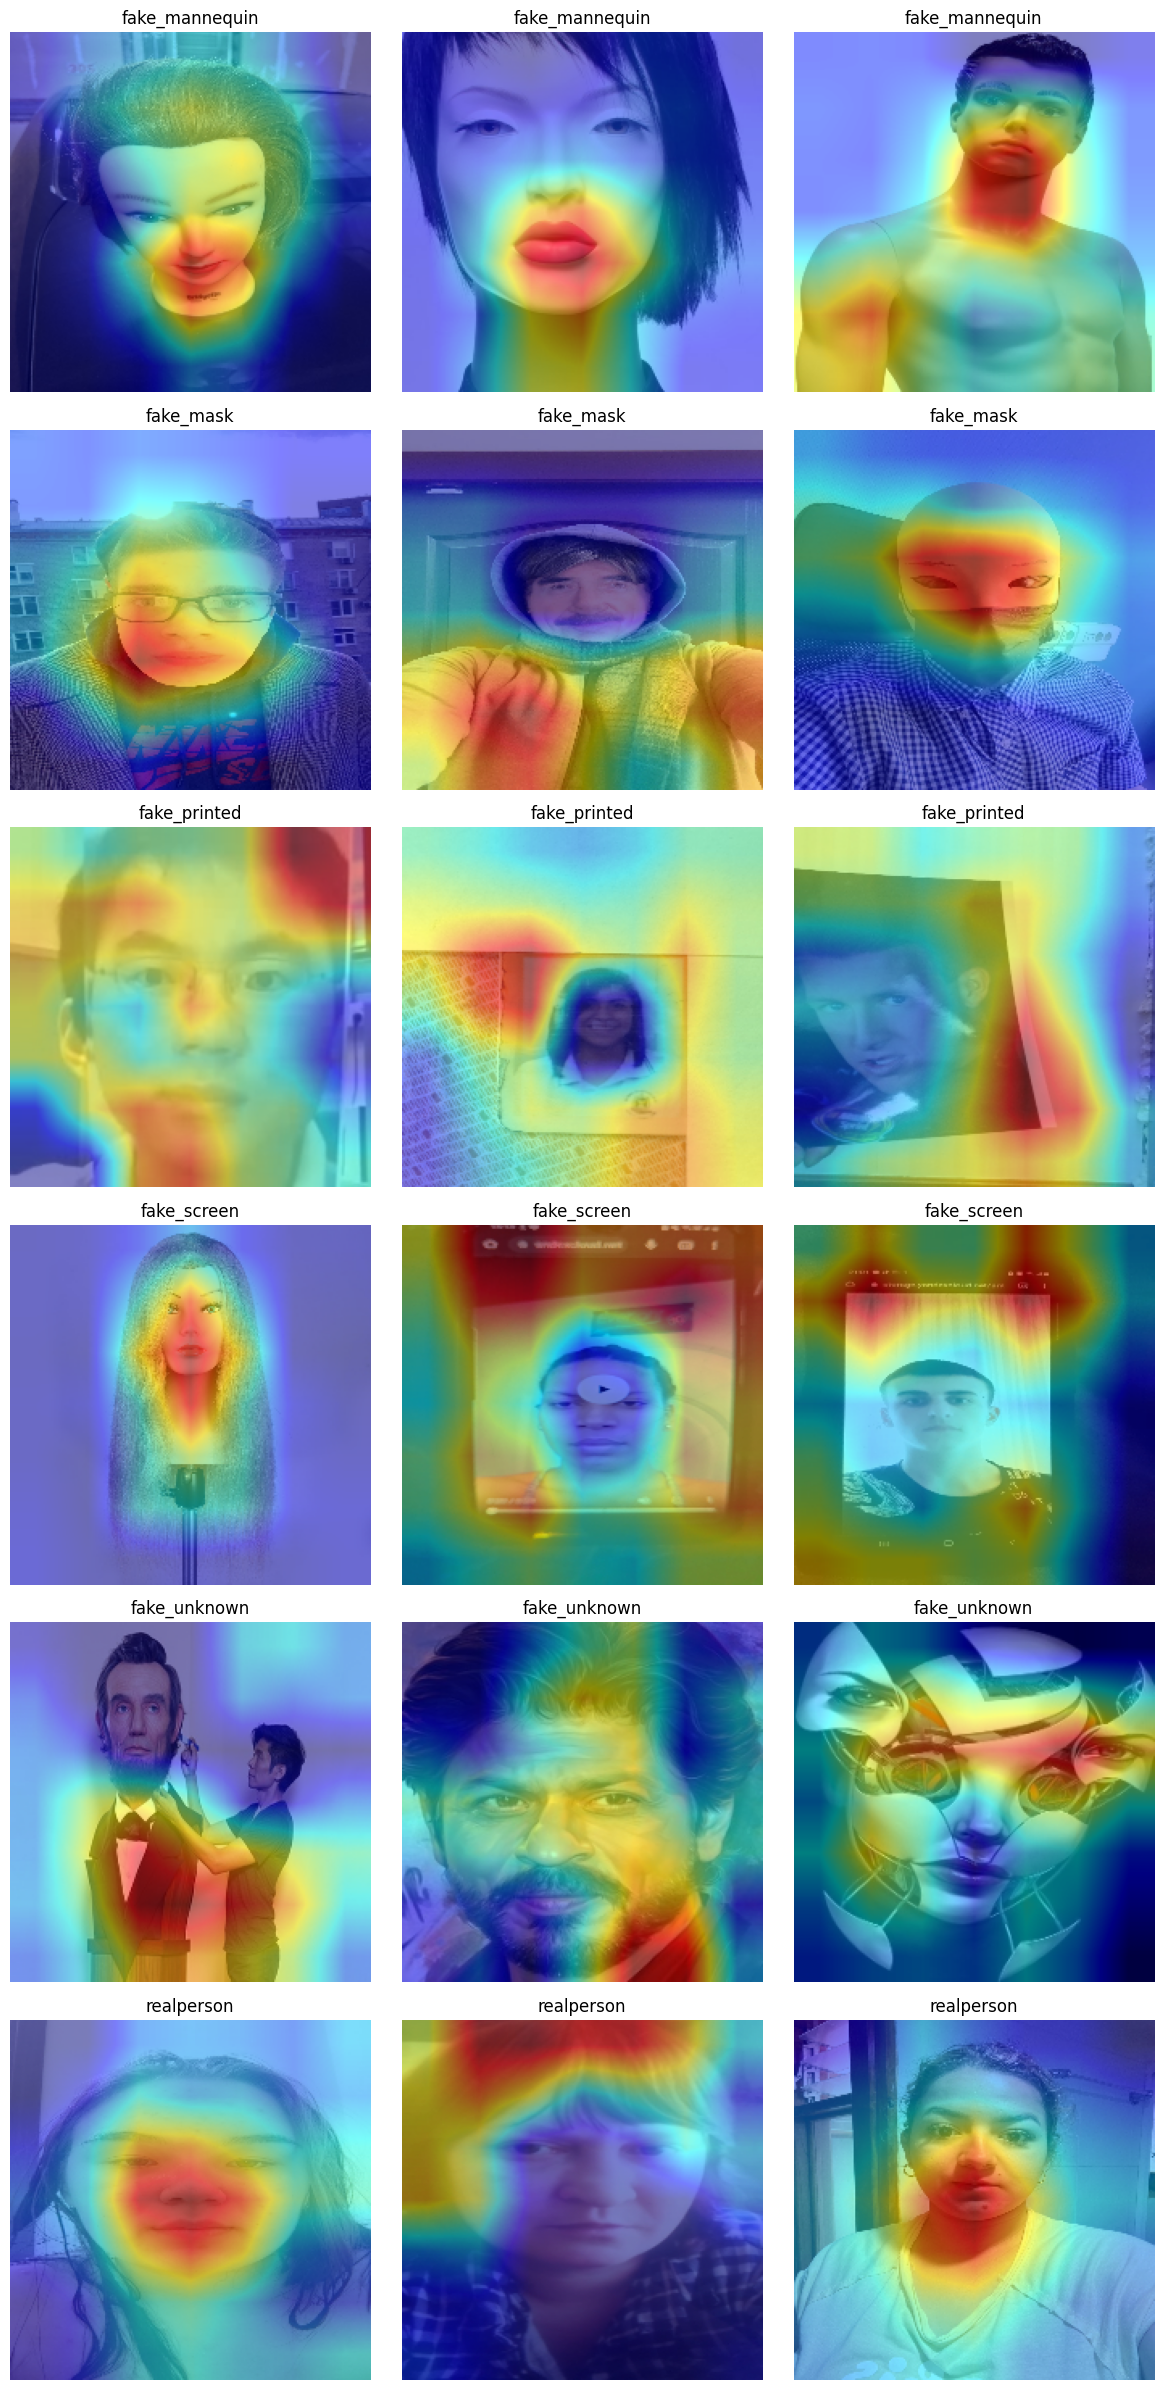

In [23]:
def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    img = std * img + mean
    return np.clip(img, 0, 1)

def show_gradcam_per_class(model, dataset, label_encoder, classes_to_show, samples_per_class=3):
    model.eval()
    fig, axes = plt.subplots(len(classes_to_show), samples_per_class,
                              figsize=(4*samples_per_class, 4*len(classes_to_show)))
    if len(classes_to_show) == 1:
        axes = axes[np.newaxis, :]

    for row, class_name in enumerate(classes_to_show):
        class_id = list(label_encoder.classes_).index(class_name)
        indices = dataset.df[dataset.df['class_id'] == class_id].index.tolist()
        chosen = random.sample(indices, min(samples_per_class, len(indices)))

        for col, idx in enumerate(chosen):
            img_tensor, target_class, _ = dataset[idx]
            input_tensor = img_tensor.unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                logits = model(input_tensor)
                probs = F.softmax(logits, dim=1)
                pred_id = int(torch.argmax(probs, dim=1).item())
                conf = float(probs[0, pred_id].item() * 100.0)
                pred_name = label_encoder.classes_[pred_id]

            grayscale_cam = gradcam(input_tensor=input_tensor, targets=None)[0]
            rgb_img = denormalize(img_tensor)
            visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

            axes[row, col].imshow(visualization)
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if col == 0:
                axes[row, col].set_ylabel(class_name, fontsize=11, fontweight='bold')
            axes[row, col].set_title(f"GT: {class_name}\nPred: {pred_name} ({conf:.1f}%)", fontsize=10)

    plt.tight_layout()
    plt.show()

classes_available = list(label_encoder.classes_)
show_gradcam_per_class(model, test_dataset, label_encoder, classes_available, samples_per_class=3)


Interpretasi hasil Grad CAM di atas sebaiknya dibaca sebagai berikut. Area yang berwarna hangat (merah dan kuning) menunjukkan piksel yang paling berkontribusi terhadap keputusan model. Untuk kelas `realperson`, area panas yang wajar berada di sekitar tekstur kulit, mata, dan bentuk wajah alami. Untuk kelas seperti `fake_mask`, area panas yang mengindikasikan model bekerja dengan benar biasanya berada di sekitar tepi masker, tekstur yang tidak alami, atau area mata dan mulut yang terlihat janggal. Untuk kelas spoof hasil foto atau rekam layar, area panas yang relevan biasanya berada pada pantulan cahaya layar, moire pattern, atau tepi bingkai perangkat yang ikut terekam.

## 19. Fungsi Inference untuk Data Baru
Fungsi berikut siap dipakai pada data baru di luar dataset training, baik untuk satu gambar maupun banyak gambar sekaligus (batch). Fungsi ini memuat kembali checkpoint model terbaik, melakukan preprocessing yang identik dengan preprocessing saat evaluasi, lalu mengembalikan prediksi kelas granular, label keamanan Real atau Spoof, beserta skor keyakinan (confidence).

In [24]:
def load_model_for_inference(checkpoint_path, device=DEVICE):
    ckpt = torch.load(checkpoint_path, map_location=device)
    classes = ckpt['label_encoder_classes']
    num_classes = len(classes)

    inference_model = EfficientNetModel(num_classes=num_classes, pretrained=False)
    inference_model.load_state_dict(ckpt['model_state_dict'])
    inference_model.to(device)
    inference_model.eval()

    return inference_model, classes, ckpt.get('img_size', 224)


def preprocess_image(image_path_or_array, img_size):
    if isinstance(image_path_or_array, str):
        img = cv2.imread(image_path_or_array)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    else:
        img = image_path_or_array

    transform = A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])
    return transform(image=img)['image']


@torch.no_grad()
def predict(image_paths, model=None, classes=None, img_size=224,
            checkpoint_path=None, spoof_class_names=None, device=DEVICE):
    # Muat model apabila belum disediakan langsung
    if model is None:
        if checkpoint_path is None:
            checkpoint_path = best_ckpt_path
        model, classes, img_size = load_model_for_inference(checkpoint_path, device)

    if spoof_class_names is None:
        spoof_class_names = [c for c in classes if not c.lower().startswith('realperson')]

    if isinstance(image_paths, str):
        image_paths = [image_paths]

    batch_tensors = torch.stack([preprocess_image(p, img_size) for p in image_paths]).to(device)
    logits = model(batch_tensors)
    probs = F.softmax(logits, dim=1).cpu().numpy()

    results = []
    for path, prob in zip(image_paths, probs):
        pred_id = int(np.argmax(prob))
        pred_class = classes[pred_id]
        confidence = float(prob[pred_id])
        security_label = 'Real' if pred_class.lower().startswith('realperson') else 'Spoof'

        results.append({
            'filepath': path,
            'predicted_class': pred_class,
            'security_label': security_label,
            'confidence': round(confidence, 4),
            'probability_per_class': {c: round(float(p), 4) for c, p in zip(classes, prob)}
        })

    return results if len(results) > 1 else results[0]

In [25]:
# Contoh pemakaian fungsi inference pada beberapa gambar dari test set
sample_paths = test_df['filepath'].sample(3, random_state=SEED).tolist()
inference_model, classes, img_size = load_model_for_inference(best_ckpt_path)

predictions = predict(sample_paths, model=inference_model, classes=classes, img_size=img_size)
for p in predictions:
    print(json.dumps(p, indent=2))

{
  "filepath": "D:/Bagas/BootcampAI2026/Convnext/train\\realperson\\real_431.jpg",
  "predicted_class": "realperson",
  "security_label": "Real",
  "confidence": 0.7949,
  "probability_per_class": {
    "fake_mannequin": 0.087,
    "fake_mask": 0.0379,
    "fake_printed": 0.0486,
    "fake_screen": 0.0269,
    "fake_unknown": 0.0047,
    "realperson": 0.7949
  }
}
{
  "filepath": "D:/Bagas/BootcampAI2026/Convnext/train\\fake_mask\\mask_075.jpg",
  "predicted_class": "fake_mask",
  "security_label": "Spoof",
  "confidence": 0.9944,
  "probability_per_class": {
    "fake_mannequin": 0.0004,
    "fake_mask": 0.9944,
    "fake_printed": 0.0015,
    "fake_screen": 0.0021,
    "fake_unknown": 0.0006,
    "realperson": 0.001
  }
}
{
  "filepath": "D:/Bagas/BootcampAI2026/Convnext/train\\fake_mask\\mask_283.jpg",
  "predicted_class": "fake_mask",
  "security_label": "Spoof",
  "confidence": 0.3307,
  "probability_per_class": {
    "fake_mannequin": 0.1351,
    "fake_mask": 0.3307,
    "fake_p

## 20. Menyimpan Artefak Model
Selain checkpoint bobot model, konfigurasi label dan ukuran gambar juga disimpan dalam format JSON agar proses inference di masa depan (misalnya pada aplikasi terpisah) tidak bergantung pada isi notebook ini.

In [26]:
config = {
    'label_encoder_classes': label_encoder.classes_.tolist(),
    'img_size': IMG_SIZE,
    'backbone': 'efficientnet_b0',
    'classifier_head': 'linear',
    'test_macro_f1': float(test_macro_f1),
}

with open(os.path.join(ARTIFACT_DIR, 'config.json'), 'w') as f:
    json.dump(config, f, indent=2)

print('Artefak tersimpan pada:', ARTIFACT_DIR)
print(json.dumps(config, indent=2))

Artefak tersimpan pada: D:/Bagas/BootcampAI2026/Convnext/artifacts
{
  "label_encoder_classes": [
    "fake_mannequin",
    "fake_mask",
    "fake_printed",
    "fake_screen",
    "fake_unknown",
    "realperson"
  ],
  "img_size": 224,
  "backbone": "efficientnet_b0",
  "classifier_head": "linear",
  "test_macro_f1": 0.9086864364677663
}


## Kesimpulan

1. Model dibangun dengan pendekatan sederhana: backbone EfficientNet B0 pretrained langsung ke classifier Linear, tanpa proyeksi embedding maupun margin sudut (ArcFace), konsisten dengan pipeline ConvNeXt.
2. Augmentasi diset konservatif (Resize, HorizontalFlip, ColorJitter ringan) supaya sinyal tekstur halus yang membedakan jenis spoof tidak ikut rusak oleh augmentasi yang terlalu agresif.
3. Strategi anti overfitting yang dipakai mencakup weight decay, label smoothing, freeze kemudian unfreeze backbone secara bertahap, serta early stopping berdasarkan validation macro F1.
4. Strategi anti underfitting mencakup penggunaan backbone pretrained (transfer learning) dan fine tuning menyeluruh pada tahap kedua.
5. Validasi utama memakai macro F1 baik pada level granular (per jenis serangan) maupun level agregat Real dan Spoof, sehingga kelas minoritas tetap mendapat perhatian yang setara.
6. Visualisasi t SNE (memakai fitur backbone langsung) dan Grad CAM dipakai untuk memverifikasi bahwa model belajar sinyal yang relevan secara visual dan membentuk representasi fitur yang terpisah dengan baik, bukan sekadar menghafal data training.
7. Fungsi `predict` dapat langsung dipakai untuk mengklasifikasikan gambar wajah baru dan mengembalikan label keamanan Real atau Spoof beserta tingkat keyakinannya, sehingga siap diintegrasikan ke dalam sistem keamanan siber yang lebih besar.